<a href="https://colab.research.google.com/github/DalilaGallegos/Portafolio-del-Diplomado-en-Python_Gallegos_Jim-nez_Yajaira_Dalila/blob/main/01_Analisis_Exploratorio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 1. Análisis exploratorio de datos para un problema de clasificación

## Telco Customer Churn

**Metodología:** CRISP-DM  
**Tipo de problema:** Clasificación binaria  
**Variable objetivo:** `Churn`

### Objetivo del notebook

Desarrollar las primeras tres etapas de la metodología CRISP-DM sobre un conjunto de datos relacionado con una situación real:

1. Comprensión del negocio.
2. Comprensión de los datos.
3. Preparación de los datos.

El análisis se enfocará en comprender el problema del abandono de clientes de una empresa de telecomunicaciones, explorar las características del conjunto de datos e identificar y corregir posibles problemas de calidad antes de continuar posteriormente con etapas de modelado.

# 1. Comprensión del negocio

## 1.1 Descripción del problema

El conjunto de datos **Telco Customer Churn** contiene información relacionada con clientes de una empresa de telecomunicaciones. Incluye características personales, antigüedad como cliente, servicios contratados, tipo de contrato, método de pago y cargos relacionados con el servicio.

Uno de los problemas que puede enfrentar una empresa de telecomunicaciones es la pérdida de clientes. Cuando un usuario decide cancelar sus servicios y abandonar la compañía se produce lo que se conoce como **Churn**.

Analizar las características de los clientes que permanecen y de aquellos que abandonan puede permitir identificar patrones relacionados con este comportamiento.

## 1.2 Importancia y contexto

La pérdida de clientes puede afectar a una empresa debido a la reducción de usuarios y de los ingresos relacionados con los servicios contratados.

Por esta razón, resulta útil analizar si existen determinadas características de los clientes, de sus contratos o de los servicios utilizados que se presenten con mayor frecuencia entre quienes abandonan la compañía.

Este análisis no pretende determinar las causas del abandono, sino identificar patrones y asociaciones existentes dentro de los datos disponibles.

## 1.3 Pregunta de análisis

La pregunta principal que orientará el análisis es:

**¿Existen características de los clientes y de los servicios que tienen contratados que se encuentren asociadas con el abandono de la compañía de telecomunicaciones?**

## 1.4 Objetivo general

Analizar las características de los clientes de una empresa de telecomunicaciones mediante las primeras etapas de la metodología CRISP-DM, con el propósito de identificar patrones asociados con el abandono del servicio y preparar un conjunto de datos limpio para análisis posteriores.

## 1.5 Variable que se pretende clasificar

La variable de interés es `Churn`, la cual indica si un cliente abandonó o permaneció en la compañía.

Esta variable presenta dos categorías:

- `No`: el cliente permaneció en la compañía.
- `Yes`: el cliente abandonó la compañía.

Debido a que existen únicamente dos posibles categorías, se trata de un **problema de clasificación binaria**.

## 1.6 Utilidad del análisis

La información obtenida mediante este análisis podría utilizarse posteriormente como base para desarrollar modelos predictivos orientados a identificar clientes con mayor riesgo estimado de abandonar el servicio.

También podría aportar información útil para estudiar estrategias de atención, contratación y retención de clientes.

Sin embargo, las relaciones encontradas durante el análisis exploratorio deben interpretarse como asociaciones presentes en los datos y no necesariamente como relaciones de causa y efecto.

# 2. Comprensión de los datos

En esta etapa se explorará el conjunto de datos para conocer su estructura, dimensiones, variables, tipos de datos y distribución.

También se revisará la presencia de valores faltantes, registros duplicados y posibles inconsistencias, además de obtener estadísticas descriptivas y generar visualizaciones que permitan comprender mejor el comportamiento de los datos.

## 2.1 Origen del conjunto de datos

El conjunto de datos utilizado es **Telco Customer Churn**, obtenido de la plataforma Kaggle.

El archivo utilizado se denomina:

`WA_Fn-UseC_-Telco-Customer-Churn.csv`

Cada registro representa a un cliente de una empresa de telecomunicaciones y las columnas contienen información relacionada con sus características personales, servicios contratados, condiciones comerciales y comportamiento de abandono.

## 2.2 Importación de las librerías

Se utilizarán las siguientes bibliotecas:

- **Pandas:** para cargar, explorar y transformar los datos.
- **Matplotlib:** para generar visualizaciones.
- **Seaborn:** para crear gráficos estadísticos.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2.3 Conexión con Google Drive

El archivo CSV se encuentra almacenado en Google Drive. Se conectará Google Colab con Drive para poder acceder al conjunto de datos.

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


## 2.4 Carga del conjunto de datos

El archivo será importado mediante la función `read_csv()` de Pandas y almacenado en un DataFrame denominado `df`.

In [3]:
ruta = "/content/drive/MyDrive/Diplomado/Proyecto: Redes Neuronales/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(ruta)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


La visualización de las primeras filas permite comprobar que el archivo fue cargado correctamente y observar de manera preliminar cómo se encuentran organizados los registros y las variables.

## 2.5 Dimensiones del conjunto de datos

Se utilizará el atributo `shape` para identificar el número de registros y variables presentes en el conjunto de datos.

In [4]:
print("Número de registros:", df.shape[0])
print("Número de variables:", df.shape[1])

Número de registros: 7043
Número de variables: 21


El conjunto de datos contiene **7,043 registros y 21 variables**.

Cada fila representa a un cliente de la empresa de telecomunicaciones, mientras que cada columna corresponde a una característica relacionada con el cliente, los servicios contratados o su relación comercial con la compañía.

## 2.6 Identificación de las variables

A continuación se mostrarán los nombres de las variables que forman parte del conjunto de datos.

In [5]:
for i, columna in enumerate(df.columns, start=1):
    print(f"{i}. {columna}")

1. customerID
2. gender
3. SeniorCitizen
4. Partner
5. Dependents
6. tenure
7. PhoneService
8. MultipleLines
9. InternetService
10. OnlineSecurity
11. OnlineBackup
12. DeviceProtection
13. TechSupport
14. StreamingTV
15. StreamingMovies
16. Contract
17. PaperlessBilling
18. PaymentMethod
19. MonthlyCharges
20. TotalCharges
21. Churn


## 2.7 Significado de las principales variables

Las variables del conjunto de datos incluyen información demográfica, servicios contratados, condiciones comerciales y datos de facturación.

| Variable | Significado |
|---|---|
| `customerID` | Identificador único del cliente |
| `gender` | Género del cliente |
| `SeniorCitizen` | Indica si el cliente es adulto mayor |
| `Partner` | Indica si el cliente tiene pareja |
| `Dependents` | Indica si tiene personas dependientes |
| `tenure` | Cantidad de meses que lleva como cliente |
| `PhoneService` | Indica si tiene servicio telefónico |
| `MultipleLines` | Indica si tiene múltiples líneas telefónicas |
| `InternetService` | Tipo de servicio de Internet contratado |
| `OnlineSecurity` | Indica si cuenta con seguridad en línea |
| `OnlineBackup` | Indica si cuenta con respaldo en línea |
| `DeviceProtection` | Indica si cuenta con protección de dispositivos |
| `TechSupport` | Indica si cuenta con soporte técnico |
| `StreamingTV` | Indica si tiene servicio de televisión por streaming |
| `StreamingMovies` | Indica si tiene servicio de películas por streaming |
| `Contract` | Tipo de contrato del cliente |
| `PaperlessBilling` | Indica si utiliza facturación electrónica |
| `PaymentMethod` | Método utilizado para realizar los pagos |
| `MonthlyCharges` | Cargo mensual realizado al cliente |
| `TotalCharges` | Cantidad total acumulada cobrada al cliente |
| `Churn` | Indica si el cliente abandonó o permaneció en la compañía |

## 2.8 Tipos de datos

Se utilizará `info()` para revisar los tipos de datos, número de registros y cantidad de valores no nulos en cada variable.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


El conjunto de datos contiene variables numéricas y variables almacenadas como texto.

Se observa especialmente que `TotalCharges`, aunque conceptualmente representa una cantidad monetaria, aparece almacenada como tipo `object`. Esto indica que podrían existir valores dentro de la columna que impiden que Pandas la reconozca como numérica.

También se observa que `SeniorCitizen` está almacenada como variable numérica debido a que utiliza los valores 0 y 1, aunque conceptualmente representa una variable categórica binaria.

## 2.9 Estadísticas descriptivas de las variables numéricas

Se utilizará `describe()` para obtener medidas como promedio, desviación estándar, mínimo, máximo y cuartiles de las variables reconocidas inicialmente como numéricas.

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


Las estadísticas descriptivas permiten observar la distribución general de las variables numéricas.

Entre ellas se encuentran la antigüedad del cliente (`tenure`) y los cargos mensuales (`MonthlyCharges`).

Estas medidas permiten identificar rangos, tendencias centrales y posibles valores que requieran una revisión adicional.

## 2.10 Estadísticas descriptivas de las variables almacenadas como texto

También se analizarán las variables de tipo `object` para conocer el número de valores distintos, la categoría más frecuente y su frecuencia.

In [8]:
df.describe(include="object").T

,count,unique,top,freq
customerID,7043,7043,3186-AJIEK,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


La mayoría de las variables almacenadas como `object` corresponden a características categóricas.

Sin embargo, también aparece `TotalCharges`, lo que confirma que esta variable está siendo interpretada como texto a pesar de representar una cantidad numérica.

Será necesario investigar esta situación antes de realizar la limpieza de los datos.

## 2.11 Revisión inicial de valores faltantes

Se utilizará `isnull()` para identificar valores registrados directamente como nulos (`NaN`).

In [9]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


La revisión inicial no identifica valores faltantes almacenados directamente como `NaN`.

Sin embargo, el hecho de que `TotalCharges` aparezca como texto sugiere que podría contener valores vacíos o caracteres que no fueron reconocidos automáticamente como valores nulos.

Por esta razón se realizará una inspección específica de esta variable.

In [10]:
espacios_total_charges = (
    df["TotalCharges"].str.strip() == ""
).sum()

print(
    "Registros con espacios en blanco en TotalCharges:",
    espacios_total_charges
)

Registros con espacios en blanco en TotalCharges: 11


Se identificaron **11 registros** en los que `TotalCharges` contiene espacios en blanco.

Estos valores no fueron detectados inicialmente como `NaN`, pero explican por qué Pandas interpreta toda la columna como texto.

Este problema será corregido posteriormente durante la etapa de preparación de los datos.

## 2.12 Inspección de los registros con problemas en `TotalCharges`

A continuación se mostrarán los registros afectados para conocer sus características.

In [11]:
df[df["TotalCharges"].str.strip() == ""][
    [
        "customerID",
        "tenure",
        "MonthlyCharges",
        "TotalCharges",
        "Churn"
    ]
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


Los registros con espacios en blanco en `TotalCharges` corresponden a clientes cuya antigüedad (`tenure`) es igual a 0 meses.

Esto sugiere que se trata de clientes sin tiempo acumulado suficiente para que se registre un cargo total.

No obstante, como el valor real de `TotalCharges` no se encuentra disponible, estos registros deberán recibir un tratamiento específico durante la limpieza.

## 2.13 Revisión de registros duplicados

Se comprobará si existen filas completamente duplicadas y también se verificará cuántos identificadores únicos de clientes existen.

In [12]:
print(
    "Registros completamente duplicados:",
    df.duplicated().sum()
)

print(
    "Cantidad de clientes únicos:",
    df["customerID"].nunique()
)

Registros completamente duplicados: 0
Cantidad de clientes únicos: 7043


No se identificaron registros completamente duplicados.

Además, existen **7,043 identificadores diferentes**, la misma cantidad que el número total de registros. Esto confirma que `customerID` funciona como identificador único de cada cliente.

## 2.14 Distribución de la variable objetivo

La variable `Churn` es la variable de interés del problema de clasificación.

Se analizará tanto la cantidad como el porcentaje de clientes pertenecientes a cada categoría.

In [13]:
conteo_churn = df["Churn"].value_counts()

porcentaje_churn = (
    df["Churn"].value_counts(normalize=True) * 100
)

print("Cantidad de clientes por categoría:")
print(conteo_churn)

print("\nPorcentaje:")
print(porcentaje_churn.round(2))

Cantidad de clientes por categoría:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Porcentaje:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


La variable objetivo presenta dos categorías:

- aproximadamente **73 %** de los clientes permanecieron en la compañía;
- aproximadamente **27 %** de los clientes abandonaron el servicio.

Esto indica que las clases no se encuentran completamente equilibradas y existe un **desbalance moderado** a favor de los clientes que permanecen.

## 2.15 Visualización 1: distribución de `Churn`

La primera visualización permitirá observar gráficamente la cantidad de clientes que permanecen y abandonan la compañía.

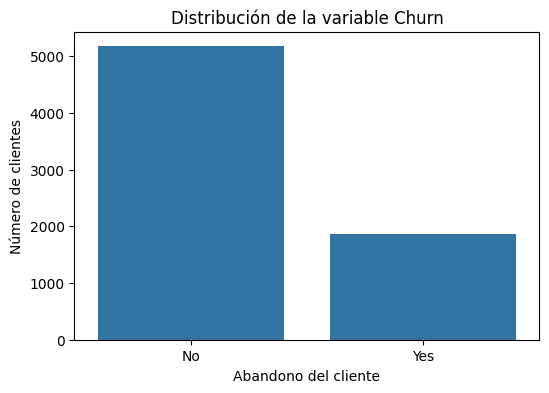

In [14]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="Churn"
)

plt.title("Distribución de la variable Churn")
plt.xlabel("Abandono del cliente")
plt.ylabel("Número de clientes")

plt.show()

La gráfica confirma visualmente que existe una mayor cantidad de clientes que permanecieron en la compañía que de clientes que abandonaron el servicio.

Esta diferencia deberá considerarse posteriormente si se desarrolla un modelo de clasificación, ya que una clase aparece con mayor frecuencia que la otra.

## 2.16 Visualización 2: abandono según tipo de contrato

Se analizará la proporción de clientes que abandonan o permanecen en la empresa según el tipo de contrato.

In [15]:
tabla_contrato = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

tabla_contrato.round(2)

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


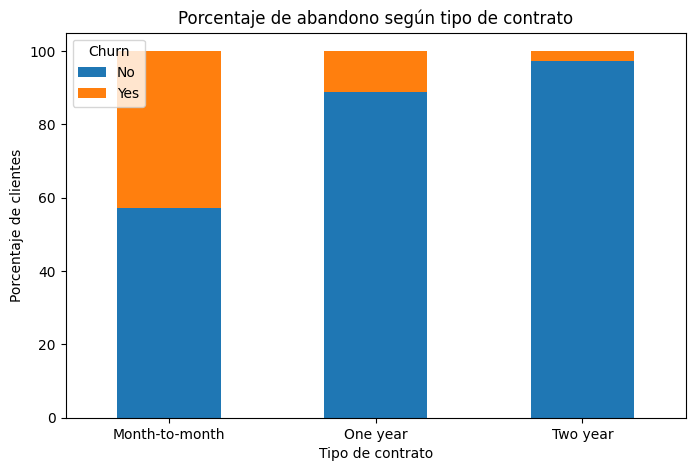

In [16]:
tabla_contrato.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Porcentaje de abandono según tipo de contrato")
plt.xlabel("Tipo de contrato")
plt.ylabel("Porcentaje de clientes")
plt.xticks(rotation=0)
plt.legend(title="Churn")

plt.show()

Se observa una diferencia importante en el comportamiento de abandono según el tipo de contrato.

Los clientes con contratos mensuales presentan una proporción de abandono mayor que quienes cuentan con contratos de uno o dos años.

Este resultado indica que existe una asociación entre el tipo de contrato y el comportamiento de abandono. Sin embargo, el análisis exploratorio no permite afirmar que el tipo de contrato sea la causa directa del abandono.

## 2.17 Visualización 3: antigüedad de los clientes según `Churn`

Se utilizará un diagrama de caja para comparar la antigüedad (`tenure`) de los clientes que permanecieron y de aquellos que abandonaron la compañía.

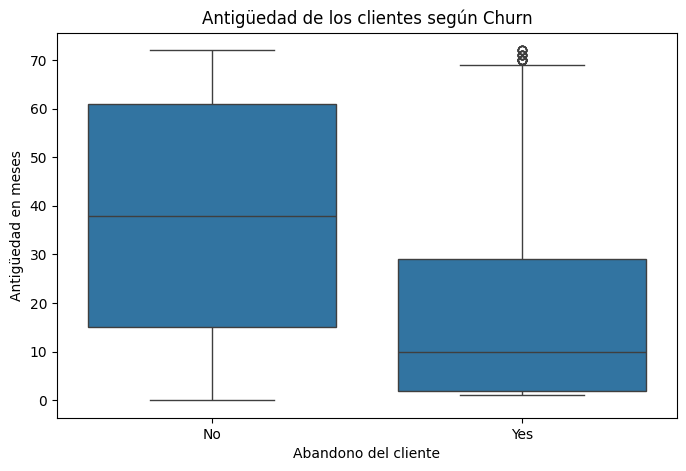

In [17]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Antigüedad de los clientes según Churn")
plt.xlabel("Abandono del cliente")
plt.ylabel("Antigüedad en meses")

plt.show()

La distribución muestra que los clientes que abandonaron la compañía tienden a concentrarse en valores menores de antigüedad.

Por otra parte, los clientes que permanecieron presentan, en general, una mayor cantidad de meses como usuarios del servicio.

Este comportamiento indica que `tenure` presenta un patrón asociado con el abandono y podría resultar relevante en análisis posteriores.

## 2.18 Principales hallazgos de la comprensión de los datos

La exploración inicial permitió identificar los siguientes aspectos:

- El conjunto de datos contiene **7,043 registros y 21 variables**.
- Cada registro corresponde a un cliente diferente.
- No existen registros completamente duplicados.
- `TotalCharges` presenta una inconsistencia de tipo de dato y contiene **11 registros con espacios en blanco**.
- La variable objetivo `Churn` presenta un desbalance moderado, debido a que aproximadamente 73 % de los clientes permanecen y 27 % abandonan la compañía.
- Los clientes con contratos mensuales presentan una mayor proporción de abandono.
- Los clientes que abandonan tienden a presentar una menor antigüedad.

Estos hallazgos permitirán orientar las decisiones de limpieza que se realizarán durante la etapa de preparación de los datos.

# 3. Preparación de los datos

Durante esta etapa se corregirán los problemas identificados en la exploración.

El objetivo es obtener un conjunto de datos limpio y consistente que pueda utilizarse posteriormente en otras etapas de la metodología CRISP-DM.

En este notebook se realizarán únicamente transformaciones relacionadas con la calidad de los datos. No se desarrollará todavía ningún modelo predictivo.

## 3.1 Creación de una copia de trabajo

Antes de modificar el conjunto de datos se creará una copia del DataFrame original.

Esto permite conservar intacta la versión inicial de los datos mientras las operaciones de limpieza se realizan sobre una nueva variable.

In [18]:
df_limpio = df.copy()

print(
    "Dimensiones iniciales:",
    df_limpio.shape
)

Dimensiones iniciales: (7043, 21)


## 3.2 Corrección del tipo de dato de `TotalCharges`

Durante la exploración se identificó que `TotalCharges` estaba almacenada como texto debido a la presencia de espacios en blanco.

La variable será convertida a formato numérico mediante `pd.to_numeric()`.

El parámetro `errors="coerce"` convertirá automáticamente en `NaN` aquellos valores que no puedan transformarse correctamente a número.

In [19]:
df_limpio["TotalCharges"] = pd.to_numeric(
    df_limpio["TotalCharges"],
    errors="coerce"
)

print(
    "Tipo de dato de TotalCharges:",
    df_limpio["TotalCharges"].dtype
)

print(
    "Valores nulos en TotalCharges:",
    df_limpio["TotalCharges"].isnull().sum()
)

Tipo de dato de TotalCharges: float64
Valores nulos en TotalCharges: 11


Después de la conversión, `TotalCharges` quedó almacenada como variable numérica y los 11 registros que contenían espacios en blanco fueron convertidos en valores `NaN`.

Estos 11 registros representan aproximadamente el **0.16 %** del conjunto de datos.

Debido a que la cantidad es muy pequeña y no se dispone de información suficiente para determinar con certeza el valor correspondiente de `TotalCharges`, se decidió eliminar estos registros en lugar de asignar valores artificiales mediante una imputación.

In [20]:
df_limpio = df_limpio.dropna(
    subset=["TotalCharges"]
).reset_index(drop=True)

print(
    "Dimensiones después del tratamiento:",
    df_limpio.shape
)

Dimensiones después del tratamiento: (7032, 21)


Después de eliminar los 11 registros afectados, el conjunto de datos quedó compuesto por **7,032 clientes**.

## 3.3 Tratamiento de registros duplicados

Aunque durante la exploración no se identificaron registros completamente duplicados, se aplicará una verificación adicional durante la preparación para garantizar que el conjunto final no contenga duplicados.

In [21]:
duplicados_antes = df_limpio.duplicated().sum()

df_limpio = (
    df_limpio
    .drop_duplicates()
    .reset_index(drop=True)
)

print(
    "Duplicados encontrados:",
    duplicados_antes
)

print(
    "Duplicados después de la limpieza:",
    df_limpio.duplicated().sum()
)

Duplicados encontrados: 0
Duplicados después de la limpieza: 0


No se encontraron registros completamente duplicados, por lo que esta operación no modificó la cantidad de observaciones.

## 3.4 Verificación de valores faltantes

Después de corregir `TotalCharges` y eliminar los registros afectados, se comprobará que no existan valores faltantes en el conjunto de datos.

In [22]:
valores_faltantes = (
    df_limpio
    .isnull()
    .sum()
)

print(valores_faltantes)

print(
    "\nTotal de valores faltantes:",
    valores_faltantes.sum()
)

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Total de valores faltantes: 0


Después del proceso de limpieza no se identificaron valores faltantes restantes en el conjunto de datos.

## 3.5 Verificación de los tipos de datos

Se realizará una nueva inspección mediante `info()` para comprobar que `TotalCharges` se encuentre ahora correctamente almacenada como variable numérica.

In [23]:
df_limpio.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7032 entries, 0 to 7031
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7032 non-null   object 
 1   gender            7032 non-null   object 
 2   SeniorCitizen     7032 non-null   int64  
 3   Partner           7032 non-null   object 
 4   Dependents        7032 non-null   object 
 5   tenure            7032 non-null   int64  
 6   PhoneService      7032 non-null   object 
 7   MultipleLines     7032 non-null   object 
 8   InternetService   7032 non-null   object 
 9   OnlineSecurity    7032 non-null   object 
 10  OnlineBackup      7032 non-null   object 
 11  DeviceProtection  7032 non-null   object 
 12  TechSupport       7032 non-null   object 
 13  StreamingTV       7032 non-null   object 
 14  StreamingMovies   7032 non-null   object 
 15  Contract          7032 non-null   object 
 16  PaperlessBilling  7032 non-null   object 


Después de la limpieza, `TotalCharges` se encuentra almacenada correctamente como variable numérica.

Las demás variables mantienen tipos de datos consistentes con la forma en que se encuentran representadas en el conjunto de datos.

La variable `SeniorCitizen` continúa almacenada como número entero debido a su codificación mediante 0 y 1, aunque conceptualmente representa una característica categórica binaria.

## 3.6 Verificación final del conjunto de datos preparado

Finalmente se comprobarán las dimensiones, valores faltantes y registros duplicados del conjunto de datos resultante.

In [24]:
print(
    "Dimensiones originales:",
    df.shape
)

print(
    "Dimensiones finales:",
    df_limpio.shape
)

print(
    "\nValores faltantes:",
    df_limpio.isnull().sum().sum()
)

print(
    "Registros duplicados:",
    df_limpio.duplicated().sum()
)

df_limpio.head()

Dimensiones originales: (7043, 21)
Dimensiones finales: (7032, 21)

Valores faltantes: 0
Registros duplicados: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3.7 Resultado de la preparación de los datos

Después del proceso de preparación, el conjunto de datos quedó compuesto por **7,032 registros y 21 variables**.

Durante esta etapa se realizaron las siguientes acciones:

- Se creó una copia del conjunto de datos original para conservarlo intacto.
- Se corrigió el tipo de dato de `TotalCharges`, convirtiéndolo de texto a formato numérico.
- Se identificaron 11 registros cuyo valor de `TotalCharges` se encontraba vacío.
- Debido a que estos registros representaban aproximadamente el 0.16 % del total y no era posible determinar sus valores reales de manera confiable, fueron eliminados.
- Se verificó nuevamente la presencia de registros duplicados.
- Se confirmó que el conjunto final no contiene valores faltantes.
- Se revisaron nuevamente los tipos de datos para comprobar la consistencia de las variables.

Con estas transformaciones, se obtuvo un conjunto de datos limpio y consistente que puede utilizarse posteriormente en las siguientes etapas de CRISP-DM.

# Conclusión

La aplicación de las primeras etapas de la metodología CRISP-DM permitió comprender el problema del abandono de clientes, conocer la estructura del conjunto de datos e identificar problemas de calidad que requerían tratamiento.

Durante la comprensión de los datos se identificaron 7,043 registros y 21 variables. También se detectó que `TotalCharges` estaba almacenada incorrectamente como texto debido a la existencia de 11 registros con espacios en blanco.

El análisis exploratorio mostró además que la variable objetivo `Churn` presenta un desbalance moderado y que existen patrones asociados con variables como el tipo de contrato y la antigüedad del cliente.

Durante la preparación se corrigió el tipo de dato de `TotalCharges`, se trataron los registros afectados y se verificó la ausencia de valores faltantes y duplicados. Como resultado, se obtuvo un conjunto final de 7,032 registros correctamente estructurados.

El conjunto de datos queda preparado para continuar posteriormente con otras etapas de CRISP-DM, como la preparación orientada al modelado, la construcción de modelos de clasificación y su evaluación.